# Student Performance Regression Models

This notebook uses the student performance dataset to build simple linear regression, multiple linear regression, and logistic regression models. The regression models predict `final_score`; logistic regression predicts `passed`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("data/student_performance_5000.csv")
data.head()

,student_id,study_hours_per_week,attendance_pct,previous_exam_score,assignment_completion_pct,sleep_hours_per_night,internet_access,tutoring_support,final_score,passed
0,1,7.28,94.28,74.88,83.79,9.16,1,0,62.16,1
1,2,9.65,98.02,41.45,98.23,8.08,1,0,97.89,1
2,3,6.45,84.56,38.40,89.33,9.06,1,0,64.42,1
3,4,5.83,100.00,62.43,95.39,5.97,1,0,62.45,1
4,5,10.43,73.37,67.98,73.78,4.90,1,0,74.92,1


## 1. Simple linear regression

Use weekly study hours as the single predictor of final score. The test-set metrics show how well the model performs on data it did not train on.

Intercept: 60.76
Study-hours coefficient: 1.14
MAE: 8.93
RMSE: 11.13
R-squared: 0.174


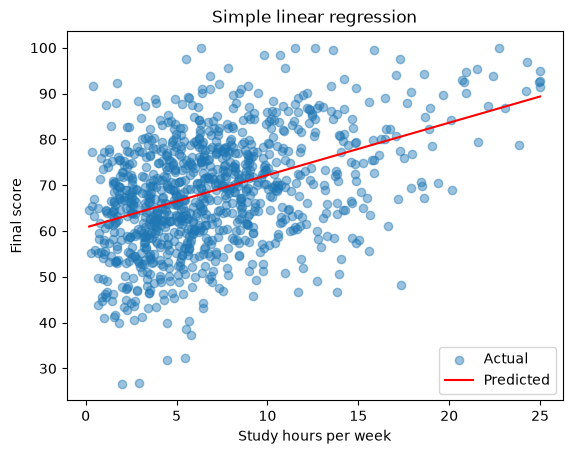

In [2]:
X_simple = data[["study_hours_per_week"]]
y_score = data["final_score"]

X_simple_train, X_simple_test, y_train, y_test = train_test_split(
    X_simple, y_score, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)
simple_predictions = simple_model.predict(X_simple_test)

print(f"Intercept: {simple_model.intercept_:.2f}")
print(f"Study-hours coefficient: {simple_model.coef_[0]:.2f}")
print(f"MAE: {mean_absolute_error(y_test, simple_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, simple_predictions)):.2f}")
print(f"R-squared: {r2_score(y_test, simple_predictions):.3f}")

plot_data = X_simple_test.assign(predicted_score=simple_predictions).sort_values(
    "study_hours_per_week"
)
plt.scatter(X_simple_test["study_hours_per_week"], y_test, alpha=0.45, label="Actual")
plt.plot(
    plot_data["study_hours_per_week"],
    plot_data["predicted_score"],
    color="red",
    label="Predicted",
)
plt.xlabel("Study hours per week")
plt.ylabel("Final score")
plt.title("Simple linear regression")
plt.legend()
plt.show()

## 2. Multiple linear regression

Use the study, attendance, previous-exam, assignment, sleep, internet-access, and tutoring variables to predict final score. `student_id` is an identifier, so it is not used as a predictor.

In [3]:
score_features = [
    "study_hours_per_week",
    "attendance_pct",
    "previous_exam_score",
    "assignment_completion_pct",
    "sleep_hours_per_night",
    "internet_access",
    "tutoring_support",
]
X_multiple = data[score_features]

X_multiple_train, X_multiple_test, y_train, y_test = train_test_split(
    X_multiple, y_score, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()
multiple_model.fit(X_multiple_train, y_train)
multiple_predictions = multiple_model.predict(X_multiple_test)

print(f"MAE: {mean_absolute_error(y_test, multiple_predictions):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, multiple_predictions)):.2f}")
print(f"R-squared: {r2_score(y_test, multiple_predictions):.3f}")
pd.DataFrame(
    {"feature": score_features, "coefficient": multiple_model.coef_}
).sort_values("coefficient", ascending=False)

MAE: 7.43
RMSE: 9.35
R-squared: 0.417


,feature,coefficient
6,tutoring_support,2.928298
5,internet_access,1.837411
0,study_hours_per_week,1.148506
4,sleep_hours_per_night,1.117729
2,previous_exam_score,0.325438
1,attendance_pct,0.226218
3,assignment_completion_pct,0.103532


## Regression evaluation and residual plots

The next cell reports test-set mean squared error (MSE) and R-squared for both score models. It also compares actual and predicted scores and plots residuals (actual minus predicted) for 10 observations in each test set.

Simple linear regression test-set metrics:
  Mean squared error: 123.82
  R-squared: 0.174
 Observation  Actual  Predicted  Residual
           1   75.54      62.85     12.69
           2   65.23      67.49     -2.26
           3   66.17      71.43     -5.26
           4   94.63      84.66      9.97
           5   58.09      70.29    -12.20
           6   70.21      70.14      0.07
           7   71.58      68.25      3.33
           8   57.50      67.14     -9.64
           9   67.20      68.44     -1.24
          10   48.54      65.03    -16.49
Multiple linear regression test-set metrics:
  Mean squared error: 87.36
  R-squared: 0.417
 Observation  Actual  Predicted  Residual
           1   75.54      73.16      2.38
           2   65.23      72.03     -6.80
           3   66.17      68.69     -2.52
           4   94.63      75.87     18.76
           5   58.09      79.89    -21.80
           6   70.21      67.18      3.03
           7   71.58      78.11     -6.53
           8   57.5

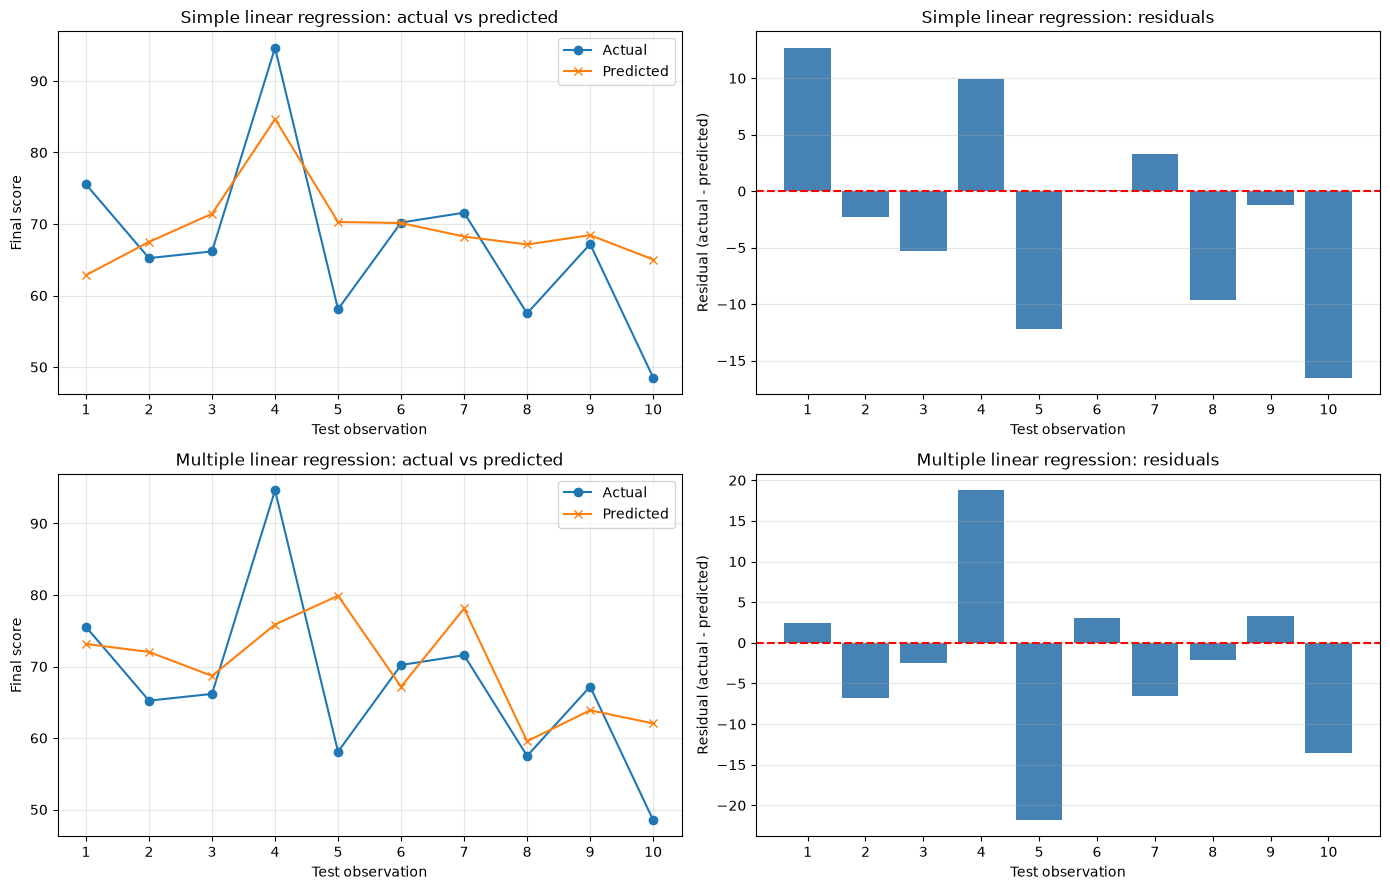

In [6]:
regression_results = {
    "Simple linear regression": (
        y_score.loc[X_simple_test.index],
        simple_model.predict(X_simple_test),
    ),
    "Multiple linear regression": (
        y_score.loc[X_multiple_test.index],
        multiple_model.predict(X_multiple_test),
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (model_name, (actual, predicted)) in enumerate(regression_results.items()):
    actual_values = actual.iloc[:10].to_numpy()
    predicted_values = predicted[:10]
    residuals = actual_values - predicted_values
    observations = np.arange(1, len(actual_values) + 1)

    print(f"{model_name} test-set metrics:")
    print(f"  Mean squared error: {mean_squared_error(actual, predicted):.2f}")
    print(f"  R-squared: {r2_score(actual, predicted):.3f}")
    print(
        pd.DataFrame(
            {
                "Observation": observations,
                "Actual": actual_values,
                "Predicted": predicted_values,
                "Residual": residuals,
            }
        ).round(2).to_string(index=False)
    )

    axes[row, 0].plot(observations, actual_values, marker="o", label="Actual")
    axes[row, 0].plot(observations, predicted_values, marker="x", label="Predicted")
    axes[row, 0].set_title(f"{model_name}: actual vs predicted")
    axes[row, 0].set_xlabel("Test observation")
    axes[row, 0].set_ylabel("Final score")
    axes[row, 0].set_xticks(observations)
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].bar(observations, residuals, color="steelblue")
    axes[row, 1].axhline(0, color="red", linestyle="--")
    axes[row, 1].set_title(f"{model_name}: residuals")
    axes[row, 1].set_xlabel("Test observation")
    axes[row, 1].set_ylabel("Residual (actual - predicted)")
    axes[row, 1].set_xticks(observations)
    axes[row, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Logistic regression

Predict whether a student passed using the same input variables. `final_score` is intentionally excluded because `passed` is determined directly by the final score; including it would leak the answer into the model. Features are standardized as part of the model pipeline, and balanced class weights help address the dataset's relatively small failing-student group.

In [5]:
X_classification = data[score_features]
y_passed = data["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y_passed,
    test_size=0.2,
    random_state=42,
    stratify=y_passed,
)

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
)
logistic_model.fit(X_train, y_train)
pass_predictions = logistic_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, pass_predictions):.3f}")
print("Confusion matrix (rows: actual, columns: predicted):")
print(confusion_matrix(y_test, pass_predictions))
print("Classification report:")
print(classification_report(y_test, pass_predictions, zero_division=0))

Accuracy: 0.716
Confusion matrix (rows: actual, columns: predicted):
[[ 57  16]
 [268 659]]
Classification report:
              precision    recall  f1-score   support

           0       0.18      0.78      0.29        73
           1       0.98      0.71      0.82       927

    accuracy                           0.72      1000
   macro avg       0.58      0.75      0.55      1000
weighted avg       0.92      0.72      0.78      1000

